# HVAC setpoint explained simply (the "like I'm 8" version of `lab-3-in-depth.ipynb`)

Same sheet (**App 2.3, Optimization of HVAC setpoint**), same numbers, but with pictures and everyday words.

| Part | The question in kid words |
|---|---|
| **0** | What is an HVAC machine and what does it do? |
| **1** | Can a **fan** let us keep the room a bit warmer and still feel fine? |
| **2** | On a day with **no heating or cooling**, at which hours do people feel bad? |
| **3** | In a freezing winter, what is the **lowest** heating temperature that is still comfy? |
| **4** | Do summer, autumn and winter give the same answer? |

**How it connects to the last lab:** lab 2 gave us a "comfort calculator" (PMV). Here we use that calculator again and again, like a thermometer for *feelings*, to decide how much to heat or cool.

## Short words used in this notebook

| Short word | Stands for | In simple words |
|---|---|---|
| **HVAC** | Heating, Ventilation and Air Conditioning | the machines that warm, cool and refresh the air in a building |
| **PMV** | Predicted Mean Vote | the average "how warm do I feel" vote of a group: -3 cold ... **0 just right** ... +3 hot |
| **PPD** | Predicted Percentage of Dissatisfied | how many out of 100 people would complain |
| **Category II** | comfort class of the standard | the "good enough" zone: PMV between **-0.5 and +0.5** |
| **ta** | air temperature | what the thermometer on the wall says |
| **tmr** | mean radiant temperature | how warm the **walls and windows** are (you feel them like a campfire or a cold window) |
| **v** | air speed | how fast the air moves past you; a fan makes it bigger |
| **RH** | relative humidity | how "wet" the air is, in % |
| **clo** | clothing unit | how warm your clothes are (0.5 = light summer clothes, 1.0 = winter sweater) |
| **met** | metabolic rate | how fast your body's engine runs (1.2 = sitting at a desk) |
| **setpoint** | the target | the temperature you tell the heater to hold |

# Part 0: What is HVAC?

**HVAC** = **H**eating + **V**entilation + **A**ir **C**onditioning. It is the team of machines that keeps a building pleasant.

| Letter | Job | Everyday picture |
|---|---|---|
| **H**eating | add warmth in winter | a campfire inside a pipe |
| **V**entilation | swap stale air for fresh air | opening a window, but with a fan |
| **A**C | remove heat (and water) in summer | a fridge for a whole room |

## The pieces

* **Boiler / heat pump / chiller** make the hot or cold water or air.
* **Ducts and pipes** carry it around, like the veins in a body.
* **The thermostat** (a sensor plus a brain) decides when to switch things on.

![How heat and cold travel from the machines to the room](images/hvac-system.svg)

*Figure: How heat and cold travel from the machines to the room*

![The air handling unit: a box that cleans, warms, cools and pushes the air](images/ahu.svg)

*Figure: The air handling unit: a box that cleans, warms, cools and pushes the air*

## Words you will see

* **Setpoint** = the number you wish for, "keep it at 23 degC".
* **Deadband** = a small gap where nothing switches on. Like not putting on and taking off your jacket every minute.
* **Thermostat vs PMV:** a normal thermostat looks at **one** thing, the air temperature. But **you** feel six things: air temperature, wall temperature, air speed, wetness, clothes and activity. PMV is one number that mixes all six. A smart controller uses PMV to find the **cheapest** setting that people still like.

![The thermostat idea: measure, compare with the target, act](images/control-loop.svg)

*Figure: The thermostat idea: measure, compare with the target, act*

![A small gap around the target stops constant switching](images/deadband.svg)

*Figure: A small gap around the target stops constant switching*

![Six things decide if a person feels comfortable](images/pmv-six-factors.svg)

*Figure: Six things decide if a person feels comfortable*

![Your body is a little heater that gives heat away](images/body-heat-exchange.svg)

*Figure: Your body is a little heater that gives heat away*

![From cold to hot: the comfort scale](images/pmv-scale.svg)

*Figure: From cold to hot: the comfort scale*

![Cold windows make you feel cold even in warm air](images/radiant-cold-window.svg)

*Figure: Cold windows make you feel cold even in warm air*

## Why comfort and energy are linked

Every degree of extra heating costs roughly **6 to 10 %** more energy (a common rule of thumb; it depends on the building). So if we can keep people happy at 21 degC instead of 23 degC, we **save energy for free**. That is the whole point of this sheet.

![From a simple switch to a learning controller](images/control-levels.svg)

*Figure: From a simple switch to a learning controller*

# Setup

In [1]:
import sys; sys.path.insert(0, "../shared")  # folder holding hvac_setpoint.py and calculate_pmv_ppd.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hvac_setpoint import (pmv, ppd, fan_sensitivity, load_day, free_running_day, hours_outside,
                           lowest_setpoint, lowest_setpoint_while, setpoint_vs_tmr, seasons_table, SEASONS)

BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
CSV = "../date_cladire_24h.csv"      # 24 hourly rows: ta, tmr, RH

The helper functions only **return numbers** (they never print or draw). `pmv(ta, tmr, ...)` is the comfort calculator, and everything below just asks it questions.

**How to read a PMV number:** -3 cold, -2 cool, -1 slightly cool, **0 just right**, +1 slightly warm, +2 warm, +3 hot. **PPD** never goes below 5 %, because you can never please everybody.

# Part 1: Can a fan let the room be warmer?

**Idea.** Moving air takes heat off your skin, the way you feel cooler when you blow on hot soup. So with a fan we can set the air temperature **higher** and feel the **same**.

**Setup (summer office):** light clothes (clo 0.5), desk work (met 1.2), RH 50 %, walls 1 degree warmer than the air.

**Recipe:**
1. Still air (0.1 m/s) at **25 degC**: write down the comfort vote.
2. Turn the air speed up from 0.1 to 0.8 m/s.
3. For each speed, find the air temperature that gives **the same vote** as in step 1.

![A fan makes you feel cooler, so the room can be warmer](images/ceiling-fan.svg)

*Figure: A fan makes you feel cooler, so the room can be warmer*

In [2]:
p1 = fan_sensitivity()                              # returns a table
print(f"Vote with still air at 25 degC: PMV = {p1.attrs['pmv_ref']:.3f}")
p1.round(2).rename(columns={"v": "air speed [m/s]", "ta_same_pmv": "warmest ta, same vote [degC]", "gain": "gain [K]",
                            "ta_at_limit": "ta at PMV 0.5 [degC]", "pmv_if_ta_unchanged": "PMV if we stay at 25"})

Vote with still air at 25 degC: PMV = 0.278


,air speed [m/s],"warmest ta, same vote [degC]",gain [K],ta at PMV 0.5 [degC],PMV if we stay at 25
0,0.1,25.00,-0.00,25.74,0.28
1,0.2,25.78,0.78,26.45,0.02
2,0.3,26.23,1.23,26.86,-0.17
3,0.4,26.58,1.58,27.18,-0.30
4,0.5,26.81,1.81,27.39,-0.41
5,0.6,27.00,2.00,27.56,-0.50
6,0.7,27.15,2.15,27.70,-0.58
7,0.8,27.28,2.28,27.82,-0.65


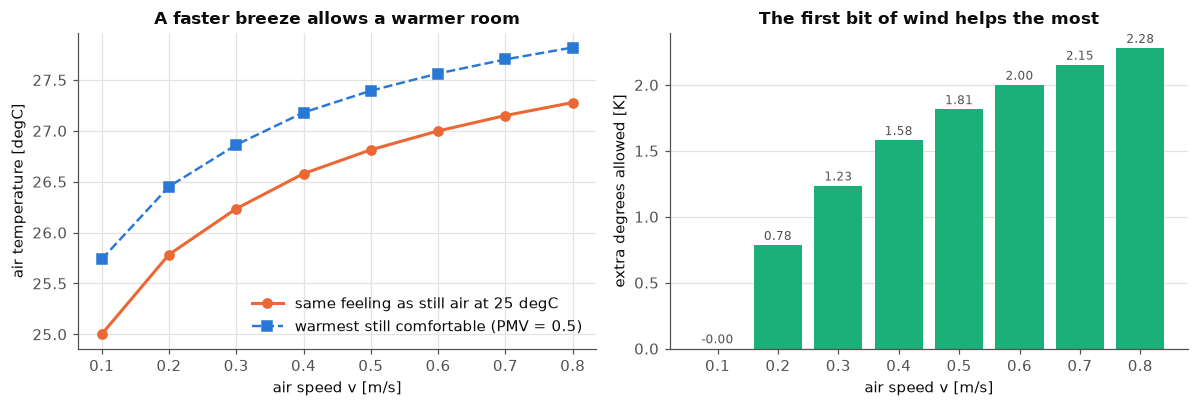

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(p1.v, p1.ta_same_pmv, "o-", color=ORANGE, lw=2, label="same feeling as still air at 25 degC")
ax[0].plot(p1.v, p1.ta_at_limit, "s--", color=BLUE, lw=1.6, label="warmest still comfortable (PMV = 0.5)")
ax[0].set_xlabel("air speed v [m/s]"); ax[0].set_ylabel("air temperature [degC]"); ax[0].legend(frameon=False)
ax[0].set_title("A faster breeze allows a warmer room")
ax[1].bar(p1.v.astype(str), p1.gain, color=AQUA)
for i, g in enumerate(p1.gain): ax[1].text(i, g + 0.04, f"{g:.2f}", ha="center", color=MUTED, fontsize=8)
ax[1].set_xlabel("air speed v [m/s]"); ax[1].set_ylabel("extra degrees allowed [K]"); ax[1].grid(axis="x", visible=False)
ax[1].set_title("The first bit of wind helps the most")
plt.tight_layout(); plt.show()

**What this means.**
* With the fan at 0.8 m/s the room can be **27.3 degC instead of 25 degC**, that is **2.3 degrees warmer** for the same feeling.
* The first push of air (0.1 to 0.2 m/s) buys **0.78 degrees**. The last push (0.7 to 0.8) buys only **0.13**. The fan has less and less to give, like the first bite of a cake tasting best. That is why ceiling fans run gently (0.3 to 0.6 m/s).
* **Energy:** 2 degrees warmer cooling target is roughly **12 to 20 % less cooling energy** (rule of thumb), and a ceiling fan only uses a few tens of watts.
* The last column warns us: if we turn the fan on **and keep 25 degC**, the vote drops to **-0.65**, which means people get a bit chilly. We would waste energy over-cooling.

# Part 2: When does the building feel bad on its own?

**Idea.** We have a file with one row for each hour of a spring/autumn day: air temperature, wall temperature and humidity. **No heating or cooling is running.** For each hour we ask the comfort calculator for a vote, then mark the hours outside the "good" zone (-0.5 to +0.5).

**Our guess for the people** (the sheet does not say): light indoor clothes for a transition day, clo 0.7, desk work (met 1.2), still air (0.1 m/s).

In [4]:
day = free_running_day(load_day(CSV), clo=0.7, met=1.2, v=0.1)    # adds pmv, ppd, t_o and a status for every hour
cold, warm = hours_outside(day)
print("too cold hours:", cold)
print("too warm hours:", warm)
print(f"Comfortable {24 - len(cold) - len(warm)} of 24 hours. Worst PMV {day.pmv.max():.2f} at hour {int(day.hour[day.pmv.idxmax()])}, "
      f"coldest PMV {day.pmv.min():.2f} at hour {int(day.hour[day.pmv.idxmin()])}")
day.round(2)

too cold hours: [0, 1, 2, 3, 4]
too warm hours: [9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Comfortable 9 of 24 hours. Worst PMV 1.35 at hour 13, coldest PMV -0.69 at hour 2


,hour,ta,tmr,rh,pmv,ppd,t_o,status
0,0,20.5,21.6,62.5,-0.52,10.55,21.05,too cold
1,1,20.1,21.1,65.6,-0.62,13.05,20.60,too cold
2,2,20.0,20.5,68.0,-0.69,15.02,20.25,too cold
3,3,20.1,21.2,69.5,-0.59,12.24,20.65,too cold
4,4,20.5,20.3,70.0,-0.62,13.10,20.40,too cold
5,5,21.2,21.5,69.5,-0.38,8.00,21.35,ok
6,6,22.0,22.0,68.0,-0.21,5.94,22.00,ok
7,7,23.0,22.7,65.6,0.00,5.00,22.85,ok
8,8,24.0,24.4,62.5,0.33,7.29,24.20,ok
9,9,25.0,25.3,58.9,0.56,11.60,25.15,too warm


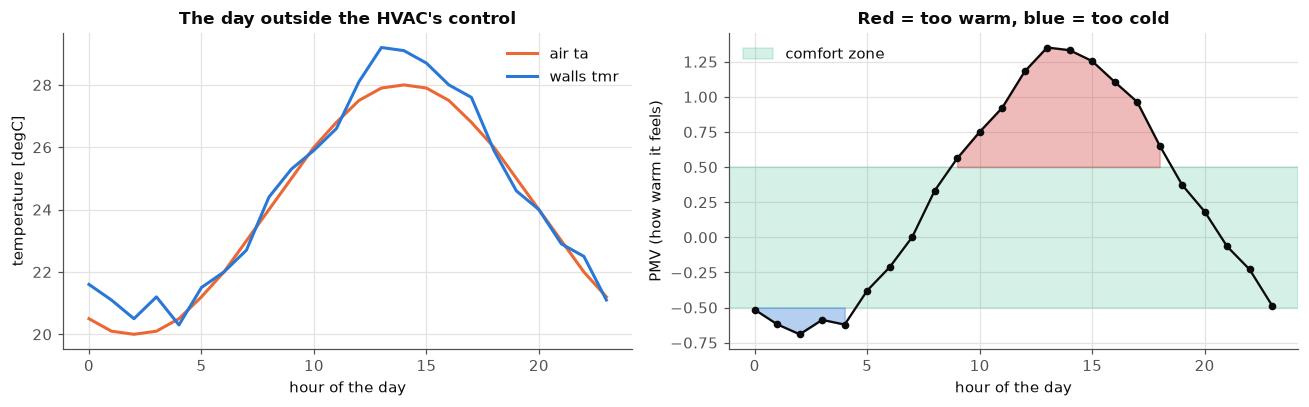

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(day.hour, day.ta, color=ORANGE, lw=2, label="air ta"); ax[0].plot(day.hour, day.tmr, color=BLUE, lw=2, label="walls tmr")
ax[0].set_xlabel("hour of the day"); ax[0].set_ylabel("temperature [degC]"); ax[0].legend(frameon=False)
ax[0].set_title("The day outside the HVAC's control")
ax[1].axhspan(-0.5, 0.5, color=AQUA, alpha=0.18, label="comfort zone")
ax[1].plot(day.hour, day.pmv, "o-", color=INK, ms=4)
ax[1].fill_between(day.hour, day.pmv, 0.5, where=day.pmv >= 0.5, color=RED, alpha=0.35)
ax[1].fill_between(day.hour, day.pmv, -0.5, where=day.pmv <= -0.5, color=BLUE, alpha=0.35)
ax[1].set_xlabel("hour of the day"); ax[1].set_ylabel("PMV (how warm it feels)"); ax[1].legend(frameon=False, loc="upper left")
ax[1].set_title("Red = too warm, blue = too cold")
plt.tight_layout(); plt.show()

**What this means.**
* Only **9 of 24 hours** are fine by themselves. The building needs help.
* **Night, hours 0 to 4: too cold** (PMV -0.52 to -0.69). The air is about 20 degC and a bit damp. Hour 2 is the worst, and 15 out of 100 people would complain.
* **Daytime, hours 9 to 18: too warm.** The sun heats the air to 28 degC and the **walls even more** (29.2 degC at hour 13). The vote reaches **+1.35** and **43 out of 100** people would complain.
* **Good hours:** 5 to 8 and 19 to 23. At hour 7 the vote is exactly 0.00, perfect. In these hours the HVAC should simply stay **off**.
* **The walls matter:** in the afternoon the walls are warmer than the air, so the room feels hotter than the wall thermometer says. A thermostat that only reads the air would be fooled.
* The same day needs **a little heating at night and cooling (or fans) in the afternoon**. A simple "winter mode / summer mode" switch would waste energy.

In [6]:
# what if people wore different clothes?
for clo in (0.5, 0.7, 1.0):
    c, w = hours_outside(free_running_day(load_day(CSV), clo=clo, met=1.2, v=0.1))
    print(f"clo {clo}: {len(c) + len(w):2d} hours outside comfort   too cold {c}   too warm {w}")

clo 0.5: 16 hours outside comfort   too cold [0, 1, 2, 3, 4, 5, 6, 22, 23]   too warm [11, 12, 13, 14, 15, 16, 17]
clo 0.7: 15 hours outside comfort   too cold [0, 1, 2, 3, 4]   too warm [9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
clo 1.0: 13 hours outside comfort   too cold []   too warm [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


**What this means.** Thin clothes (0.5) make the cold hours longer (hours 0 to 6, 22, 23). A winter sweater (1.0) removes the cold hours but makes hours 8 to 20 too warm. **Clothes change the answer**, so a smart system should know what people wear (for example from the season).

# Part 3: The lowest heating temperature that is still comfy

**Idea.** In a very cold winter the **walls and windows are cold** (here 17 degC) and the heater can only control the **air**. Cold walls steal warmth from you, like standing next to a cold window. We ask: *what is the lowest air temperature that still gives PMV >= -0.5?* Heating more than that is wasted energy.

**Setup:** winter clothes (clo 1.0), desk work (met 1.2), RH 40 %, still air (0.1 m/s), walls at 17 degC.

We solve it in two ways:
* **While loop** (a simple controller): start cold, raise the temperature in small 0.05 degree steps until the vote reaches -0.5.
* **Root finder** (`brentq`): jumps straight to the exact answer, like guessing a number with "higher / lower" hints but smartly.

In [7]:
ta_while, steps = lowest_setpoint_while(17.0, v=0.1, rh=40, clo=1.0, met=1.2)
ta_exact = lowest_setpoint(17.0, v=0.1, rh=40, clo=1.0, met=1.2)
print(f"while loop : {ta_while:.2f} degC after {steps} small steps")
print(f"root finder: {ta_exact:.3f} degC")
print(f"PMV there = {pmv(ta_exact, 17, 0.1, 40, 1.0, 1.2):.3f}, PPD = {ppd(ta_exact, 17, 0.1, 40, 1.0, 1.2):.1f} %")
print(f"Fixed 23 degC would give PMV = {pmv(23, 17, 0.1, 40, 1.0, 1.2):.2f}, PPD = {ppd(23, 17, 0.1, 40, 1.0, 1.2):.1f} %")
print(f"Saving versus the fixed 23 degC: {23 - ta_exact:.2f} K")

while loop : 21.30 degC after 226 small steps
root finder: 21.265 degC
PMV there = -0.500, PPD = 10.2 %
Fixed 23 degC would give PMV = -0.30, PPD = 6.9 %
Saving versus the fixed 23 degC: 1.74 K


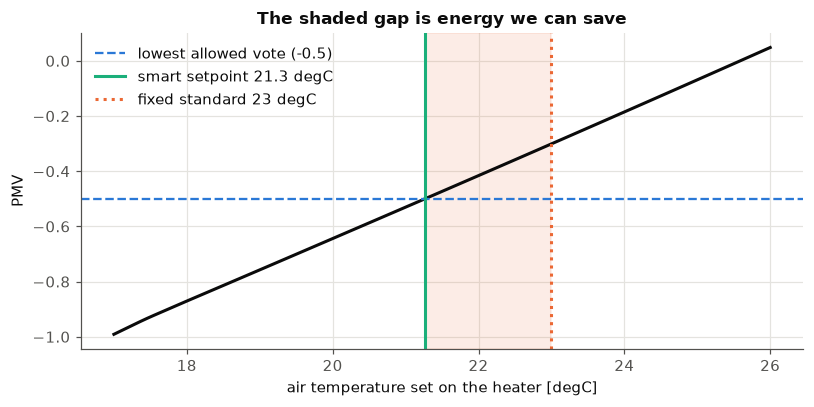

In [8]:
ta = np.linspace(17, 26, 100)
vote = [pmv(t, 17, 0.1, 40, 1.0, 1.2) for t in ta]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(ta, vote, color=INK, lw=2)
ax.axhline(-0.5, color=BLUE, ls="--", label="lowest allowed vote (-0.5)")
ax.axvline(ta_exact, color=AQUA, lw=2, label=f"smart setpoint {ta_exact:.1f} degC")
ax.axvline(23, color=ORANGE, ls=":", lw=2, label="fixed standard 23 degC")
ax.axvspan(ta_exact, 23, color=ORANGE, alpha=0.12)
ax.set_xlabel("air temperature set on the heater [degC]"); ax.set_ylabel("PMV"); ax.legend(frameon=False)
ax.set_title("The shaded gap is energy we can save")
plt.tight_layout(); plt.show()

**What this means.**
* The lowest comfortable air temperature is about **21.3 degC**. The vote is right at -0.50, and about 10 out of 100 people would complain. This is the sheet's own example (21.3 degC instead of the usual 23 degC).
* At the fixed **23 degC** the vote is **-0.30**: people are comfortable, but we heated **1.7 degrees more than needed**. With the 6 to 10 % per degree rule that is roughly **10 to 17 % less heating energy** for the same comfort.
* Both ways agree: the loop needed **226 tiny steps**, the root finder needed only a handful of tries.
* Real controllers keep a small safety margin (for example aim for -0.4) because sensors are never perfect.

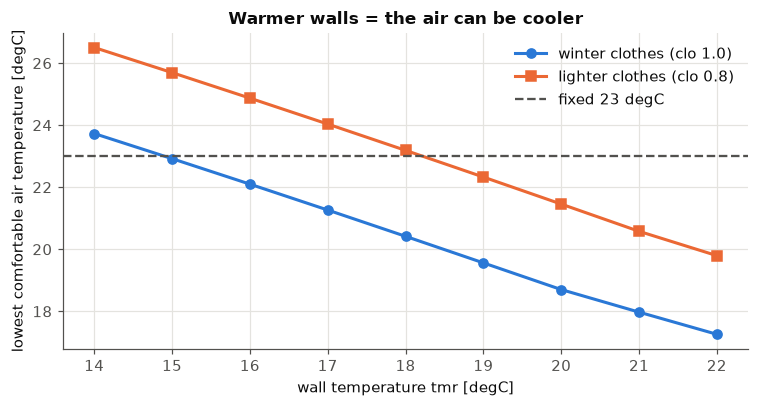

,tmr,ta_min,ta_min_light
0,14.0,23.73,26.50
1,15.0,22.92,25.69
2,16.0,22.10,24.87
3,17.0,21.26,24.04
4,18.0,20.42,23.19
5,19.0,19.56,22.33
6,20.0,18.70,21.46
7,21.0,17.97,20.58
8,22.0,17.26,19.79


In [9]:
t = setpoint_vs_tmr(np.arange(14, 22.1, 1.0), v=0.1, rh=40, clo=1.0, met=1.2)    # also a lighter clothing (clo - 0.2)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(t.tmr, t.ta_min, "o-", color=BLUE, lw=2, label="winter clothes (clo 1.0)")
ax.plot(t.tmr, t.ta_min_light, "s-", color=ORANGE, lw=2, label="lighter clothes (clo 0.8)")
ax.axhline(23, color=MUTED, ls="--", label="fixed 23 degC")
ax.set_xlabel("wall temperature tmr [degC]"); ax.set_ylabel("lowest comfortable air temperature [degC]"); ax.legend(frameon=False)
ax.set_title("Warmer walls = the air can be cooler")
plt.tight_layout(); plt.show()
t.round(2)

**What this means.**
* **Warm walls save energy:** every +1 degree on the walls lets the air be about **0.8 degree cooler** (from 23.7 degC with 14 degC walls to 18.0 degC with 21 degC walls). Better windows or insulation can beat simply turning the heater up.
* **Clothes are free heating:** going from clo 1.0 to 0.8 (a lighter sweater) forces the air to be about **2.8 degrees warmer**. Wearing the sweater costs nothing.
* If the walls are warm enough (about 15 degC and up with winter clothes) the fixed 23 degC is already **too high**; below that (14 degC walls) we actually need more than 23 degC.

# Part 4: The same question in different seasons

People dress differently and the walls behave differently in each season. So we write down a **recipe card for each season** and let the computer do the same two jobs for all of them:

1. Find the **comfort band**: the lowest and highest air temperature that stay inside PMV -0.5 to +0.5.
2. Count how many hours of our CSV day would feel bad **if people wore that season's clothes**.

| Season | clo | met | RH | v | walls tmr |
|---|---|---|---|---|---|
| summer | 0.5 | 1.2 | 50 % | 0.1 | air + 1 degree (sunny walls) |
| autumn / spring | 0.7 | 1.2 | 50 % | 0.1 | same as air |
| winter | 1.0 | 1.2 | 40 % | 0.1 | 17 degC (cold windows) |
| winter, heavy clothing | 1.2 | 1.2 | 40 % | 0.1 | 16 degC |

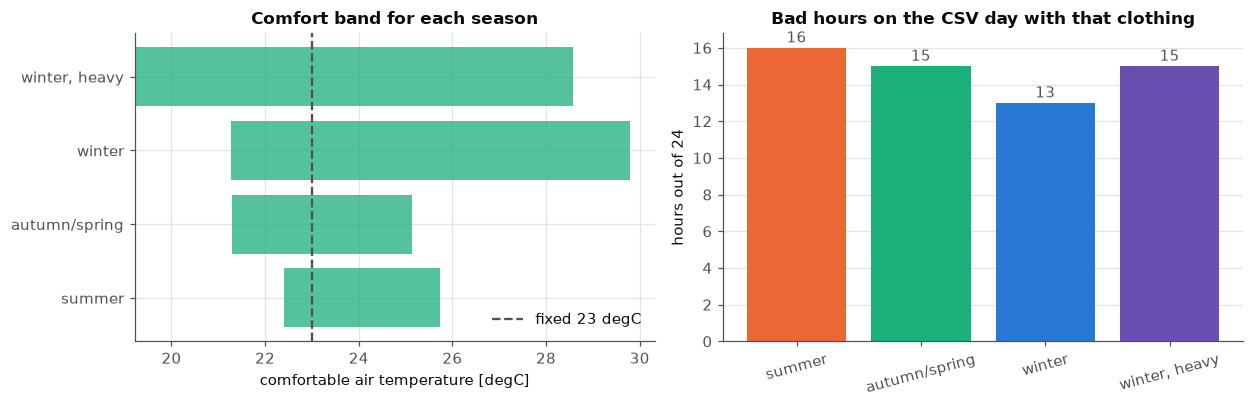

,season,ta_min,ta_max,width,hours_outside,pmv_min,pmv_max
0,summer,22.41,25.74,3.33,16,-1.23,1.16
1,autumn/spring,21.29,25.15,3.85,15,-0.69,1.35
2,winter,21.26,29.79,8.52,13,-0.16,1.54
3,"winter, heavy",19.21,28.57,9.36,15,0.12,1.66


In [10]:
p4 = seasons_table(load_day(CSV))          # uses the SEASONS recipe cards from the module
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax[0].barh(p4.season, p4.width, left=p4.ta_min, color=AQUA, alpha=0.75)
ax[0].axvline(23, color=MUTED, ls="--", label="fixed 23 degC"); ax[0].legend(frameon=False)
ax[0].set_xlabel("comfortable air temperature [degC]"); ax[0].set_title("Comfort band for each season")
ax[1].bar(p4.season, p4.hours_outside, color=[ORANGE, AQUA, BLUE, "#6b4fb0"])
for i, h in enumerate(p4.hours_outside): ax[1].text(i, h + 0.3, str(h), ha="center", color=MUTED)
ax[1].set_ylabel("hours out of 24"); ax[1].tick_params(axis="x", rotation=15); ax[1].grid(axis="x", visible=False)
ax[1].set_title("Bad hours on the CSV day with that clothing")
plt.tight_layout(); plt.show()
p4.round(2)

**What this means.**
* **The lowest comfortable temperature changes with the season:** 22.4 degC (summer), 21.3 degC (autumn/spring), 21.3 degC (winter, 17 degC walls) and 19.2 degC (winter with heavy clothes and 16 degC walls). **One fixed setpoint for the whole year can never be the cheapest.**
* **Summer has the narrowest band** (3.3 degrees, from 22.4 to 25.7 degC). Light clothes leave little room, which is where fans (Part 1) help.
* **Read winter rows for their LOWER limit only.** Their upper limits (29.8 and 28.6 degC) pretend the walls stay cold while the air is very hot, which does not happen in real buildings.
* **Bad hours on our day:** 16 (summer clothes), 15 (autumn), 13 (winter clothes), 15 (heavy winter clothes). Whatever people wear, the building fails for more than half of the day by itself, so it needs real HVAC help in both directions.
* **Two different winter assumptions, both fine:** heavier clothes and colder walls give a lower setpoint (19.2 degC vs 21.3 degC). The report should always say which assumptions were used.

# One-page summary

| Part | Main number | In one sentence |
|---|---|---|
| 1 | +2.3 K at 0.8 m/s | a fan lets us keep the room about 2 degrees warmer, with smaller and smaller gains |
| 2 | 9 of 24 h comfortable | night is slightly cold, afternoon is hot because the walls heat up |
| 3 | 21.3 degC instead of 23 degC | the smart setpoint saves about 1.7 degrees of heating |
| 4 | band 3.3 K (summer) to 8.5 K (winter) | clothes, season and wall temperature all move the best setpoint |